In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [10]:
def apply_median_filter(image, kernel_size):
    # Apply median filter to remove noise
    filtered_image = cv2.medianBlur(image, kernel_size)
    return filtered_image

def apply_bilateral_filter(image, d, sigma_color, sigma_space):
    # Apply bilateral filter to remove noise
    filtered_image = cv2.bilateralFilter(
        image, d, sigma_color, sigma_space
    )
    return filtered_image


In [11]:
image_paths = [
    'images/IMAGE1.png',
    'images/IMAGE2.png',
    'images/IMAGE3.png',
    'images/IMAGE5.png'
]

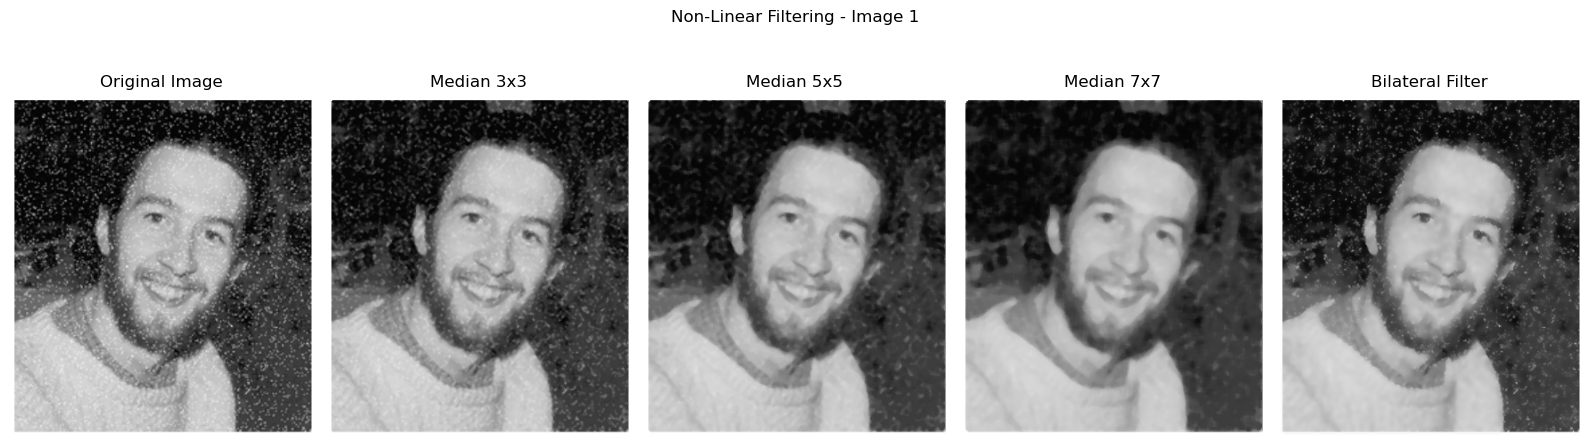

Image 1 processed successfully.


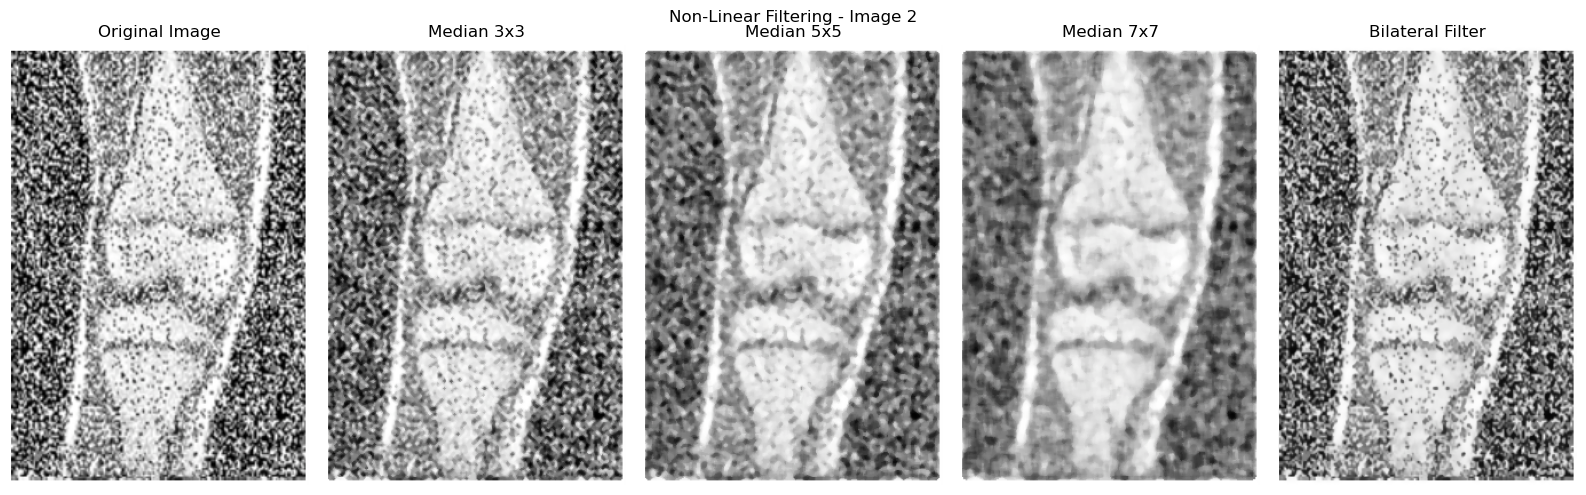

Image 2 processed successfully.


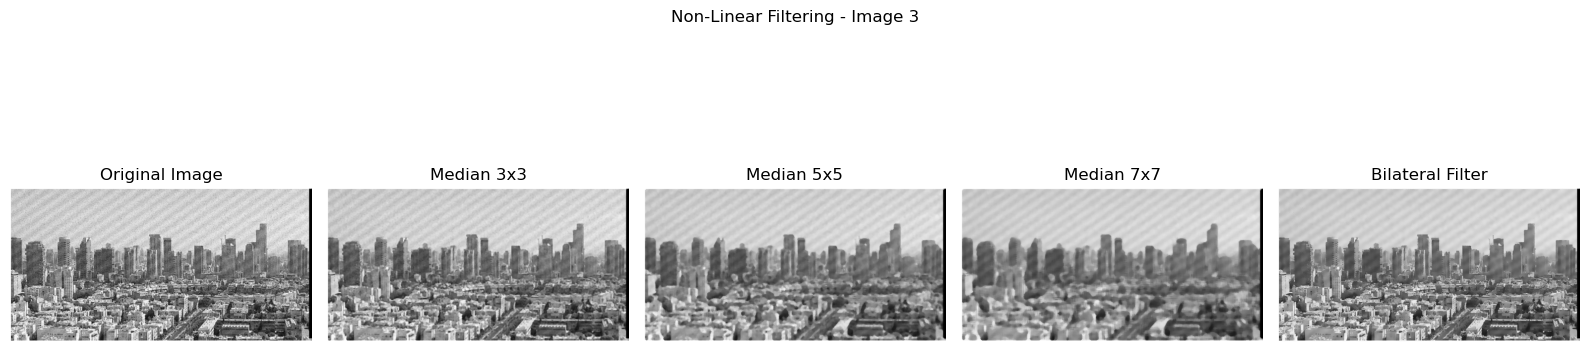

Image 3 processed successfully.


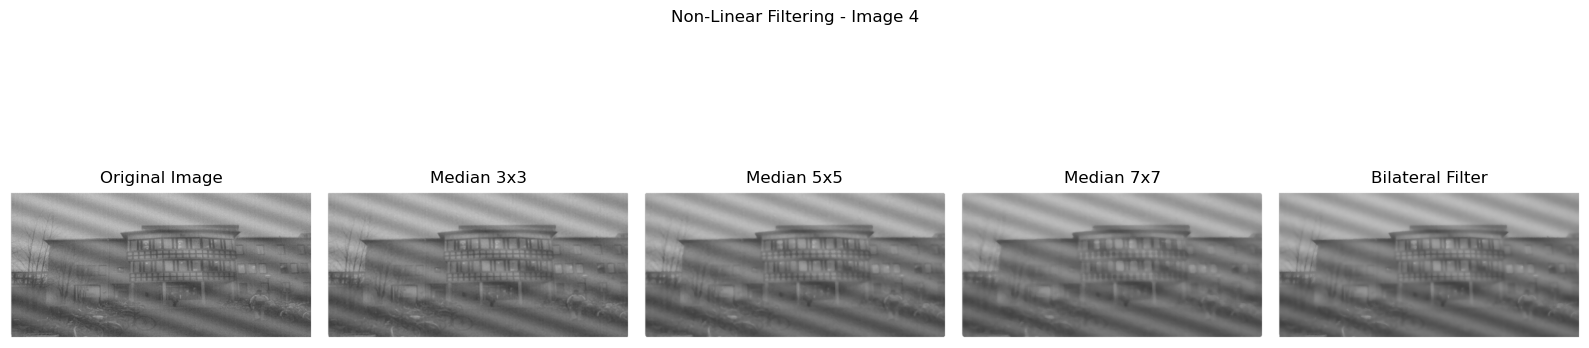

Image 4 processed successfully.
All images processed successfully!


In [ ]:
for index, image_path in enumerate(image_paths, start=1):

    # Load input image
    input_image = cv2.imread(image_path)

    if input_image is None:
        print("Image not found:", image_path)
        continue

    # Apply Median Filters
    median_3 = apply_median_filter(input_image, 3)
    median_5 = apply_median_filter(input_image, 5)
    median_7 = apply_median_filter(input_image, 7)

    # Apply Bilateral Filter
    bilateral = apply_bilateral_filter(
        input_image, 9, 75, 75
    )

    # Store filtered images
    images = [
        input_image,
        median_3,
        median_5,
        median_7,
        bilateral
    ]

    titles = [
        'Original Image',
        'Median 3x3',
        'Median 5x5',
        'Median 7x7',
        'Bilateral Filter'
    ]

    # Create separate subplot for each image
    plt.figure(figsize=(16, 5))

    for j in range(5):
        plt.subplot(1, 5, j + 1)

        rgb_image = cv2.cvtColor(
            images[j], cv2.COLOR_BGR2RGB
        )

        plt.imshow(rgb_image)
        plt.title(titles[j])
        plt.axis('off')

    plt.suptitle(f'Non-Linear Filtering - Image {index}')
    plt.tight_layout()
    plt.show()

    # Save filtered images
    cv2.imwrite(f'image{index}_median3.jpg', median_3)
    cv2.imwrite(f'image{index}_median5.jpg', median_5)
    cv2.imwrite(f'image{index}_median7.jpg', median_7)
    cv2.imwrite(f'image{index}_bilateral.jpg', bilateral)

    print(f"Image {index} processed successfully.")

print("All images processed successfully!")
